<a href="https://colab.research.google.com/github/mrayhanz/Algorithm-Data-Structure/blob/main/week10_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

Kelas : TI - 3G

Nim : 244107020027

Absen : 19

In [ ]:
NAMA = 'Muhammad Rayhan Zamzami'
NIM = '244107020027' # ganti dengan NIM sendiri
print(NAMA, NIM)

Muhammad Rayhan Zamzami 244107020027


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Import Library
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

from skimage import data, segmentation
from sklearn.cluster import KMeans
BASE = '/content/drive/MyDrive/PCVK-2026/Images'

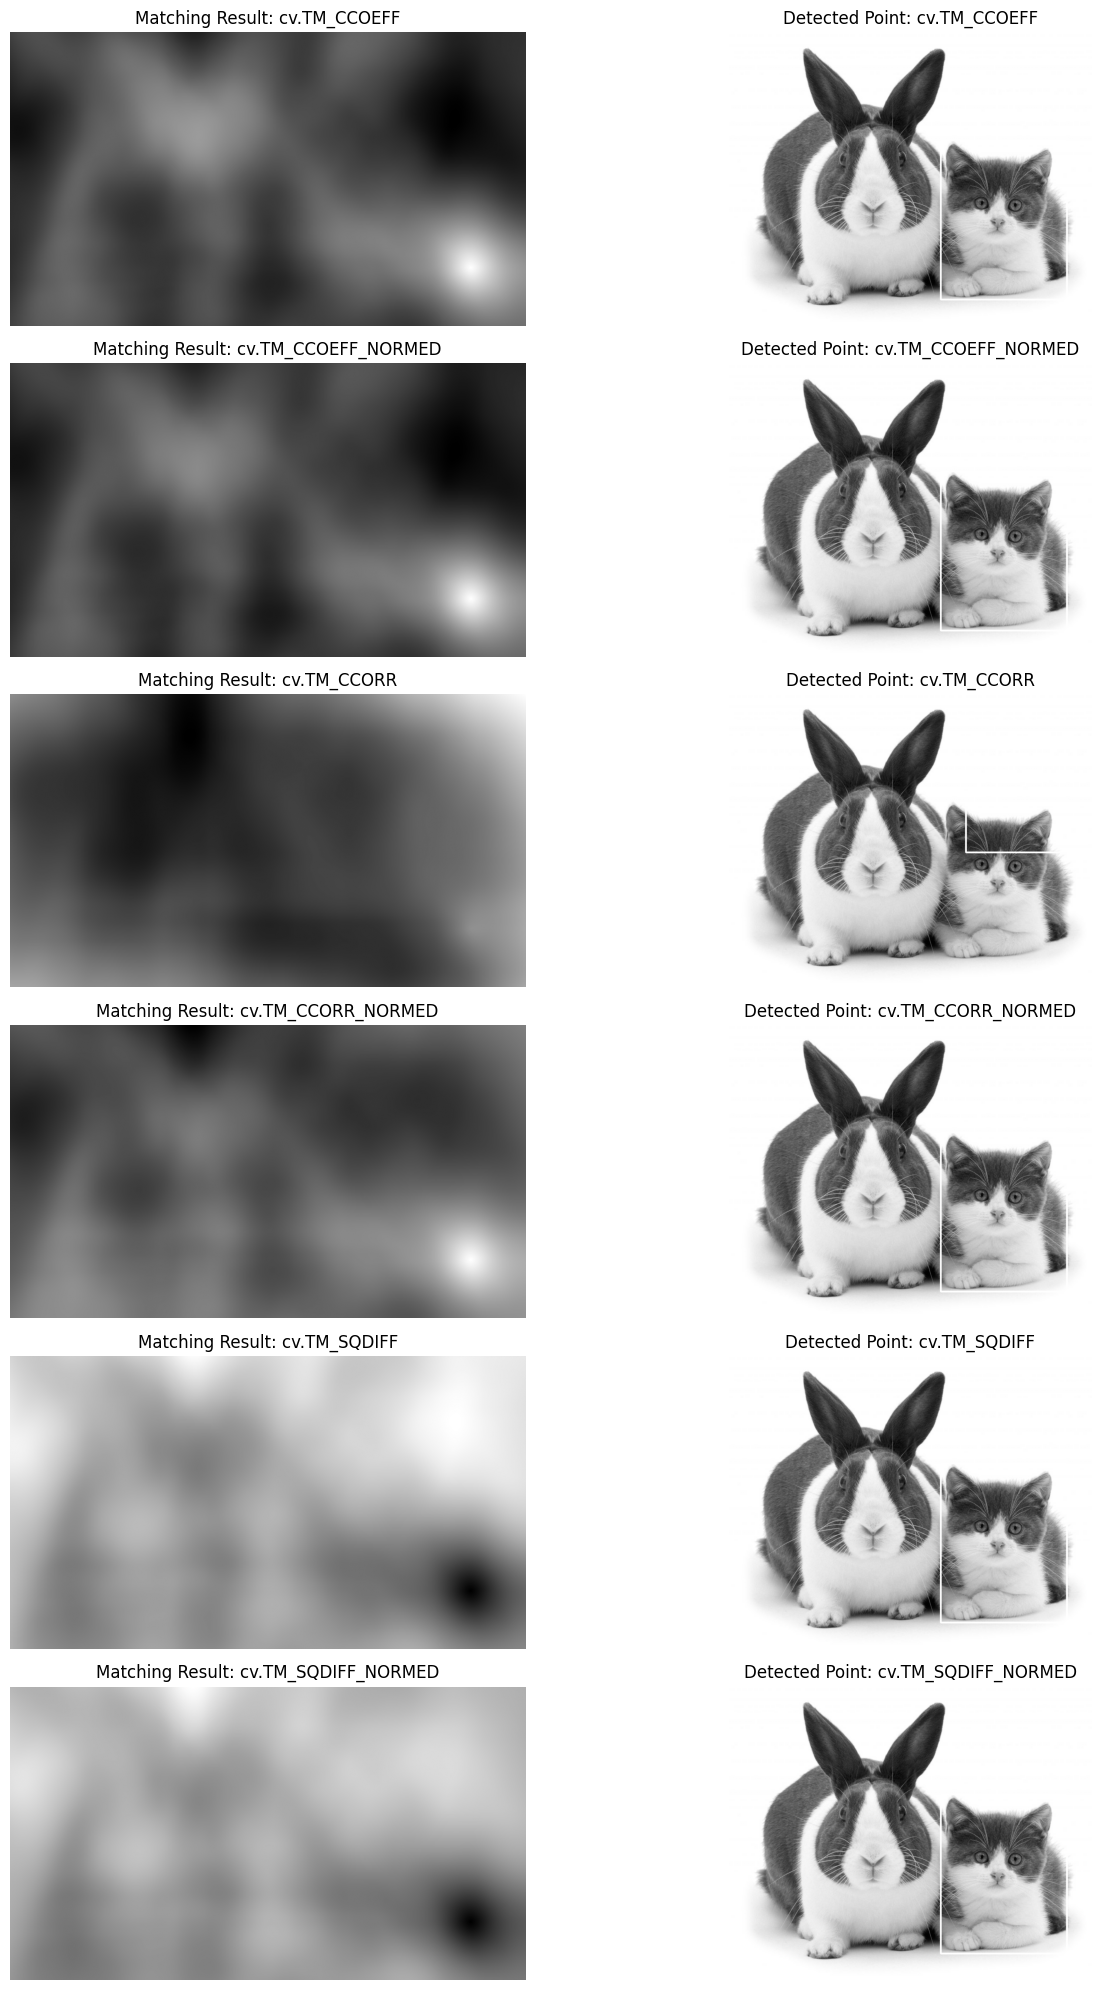

In [32]:
# 2. Implementasikan 6 metode template matching pada OpenCV
img_path = f"{BASE}/cats_and_bunnies.jpg"
template_path = f"{BASE}/cat2_templatejpg.jpg"

img = cv.imread(img_path, 0)
template = cv.imread(template_path, 0)

if img is None:
    img = cv.imread(f"{BASE}/cats_and_bunnies.png", 0)
if template is None:
    template = cv.imread(f"{BASE}/cat2_template.jpg", 0)

w, h = template.shape[::-1]

methods = [
    ('cv.TM_CCOEFF', cv.TM_CCOEFF),
    ('cv.TM_CCOEFF_NORMED', cv.TM_CCOEFF_NORMED),
    ('cv.TM_CCORR', cv.TM_CCORR),
    ('cv.TM_CCORR_NORMED', cv.TM_CCORR_NORMED),
    ('cv.TM_SQDIFF', cv.TM_SQDIFF),
    ('cv.TM_SQDIFF_NORMED', cv.TM_SQDIFF_NORMED)
]

plt.figure(figsize=(15, 20))
for i, (meth_name, meth) in enumerate(methods):
    img2 = img.copy()
    res = cv.matchTemplate(img2, template, meth)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    if meth in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)

    cv.rectangle(img2, top_left, bottom_right, 255, 3)

    plt.subplot(6, 2, 2 * i + 1)
    plt.imshow(res, cmap='gray')
    plt.title(f'Matching Result: {meth_name}')
    plt.axis('off')

    plt.subplot(6, 2, 2 * i + 2)
    plt.imshow(img2, cmap='gray')
    plt.title(f'Detected Point: {meth_name}')
    plt.axis('off')

plt.tight_layout()
plt.show()

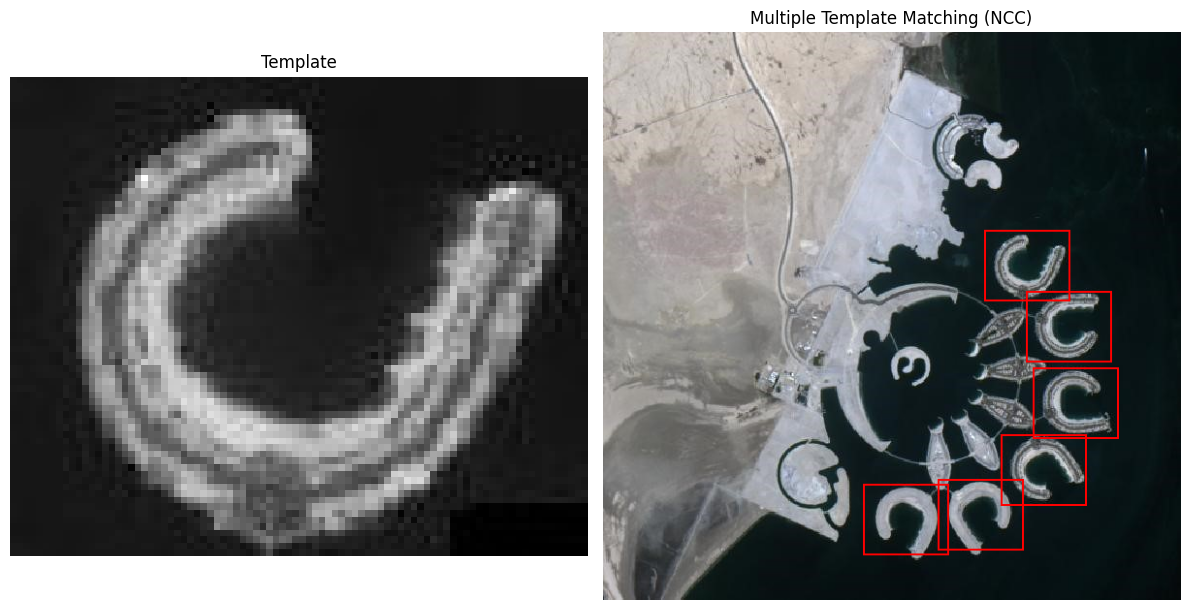

In [35]:
# 3. Multiple template matching tanpa OpenCV
from PIL import Image, ImageDraw
from scipy.signal import fftconvolve

source = Image.open(f"{BASE}/bahrain.jpg").convert('RGB')
a = np.asarray(source.convert('L'), dtype=np.float64)
t = np.asarray(Image.open(f"{BASE}/bahrain-template.jpg").convert('L'), dtype=np.float64)
h, w = t.shape
t0 = t - t.mean()
# NCC: pembilang korelasi, penyebut energi patch setelah dikurangi rata-rata.
ones = np.ones((h, w))
sums = fftconvolve(a, ones, mode='valid')
squares = fftconvolve(a*a, ones, mode='valid')
numerator = fftconvolve(a, t0[::-1, ::-1], mode='valid')
denominator = np.sqrt(np.maximum(squares - sums*sums/(h*w), 0) * np.sum(t0*t0))
response = np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator>1e-8)
# Ambang absolut dan non-maximum suppression agar kotak tidak bertumpuk.
# Cari beberapa orientasi karena pulau pada contoh modul berotasi.
base_template = Image.fromarray(t.astype(np.uint8))
for angle in range(30, 360, 30):
    rotated = np.asarray(base_template.rotate(angle, resample=Image.Resampling.BILINEAR,
                                              expand=False, fillcolor=int(np.median(t))), dtype=np.float64)
    rotated -= rotated.mean()
    num = fftconvolve(a, rotated[::-1, ::-1], mode='valid')
    den = np.sqrt(np.maximum(squares-sums*sums/(h*w), 0)*np.sum(rotated*rotated))
    rotated_score = np.divide(num, den, out=np.zeros_like(num), where=den>1e-8)
    response = np.maximum(response, rotated_score)
threshold = 0.60
scores = response.copy()
detections = []
while scores.max() >= threshold:
    y, x = np.unravel_index(np.argmax(scores), scores.shape)
    detections.append((x, y, float(scores[y, x])))
    scores[max(0,y-h//2):y+h//2+1, max(0,x-w//2):x+w//2+1] = -1
out = source.copy()
draw = ImageDraw.Draw(out)
for x, y, score in detections:
    draw.rectangle((x,y,x+w,y+h), outline='red', width=2)
plt.figure(figsize=(12,6))
plt.subplot(1,2,1); plt.imshow(t,cmap='gray'); plt.title('Template'); plt.axis('off')
plt.subplot(1,2,2); plt.imshow(out); plt.title('Multiple Template Matching (NCC)'); plt.axis('off')
plt.tight_layout(); plt.show()

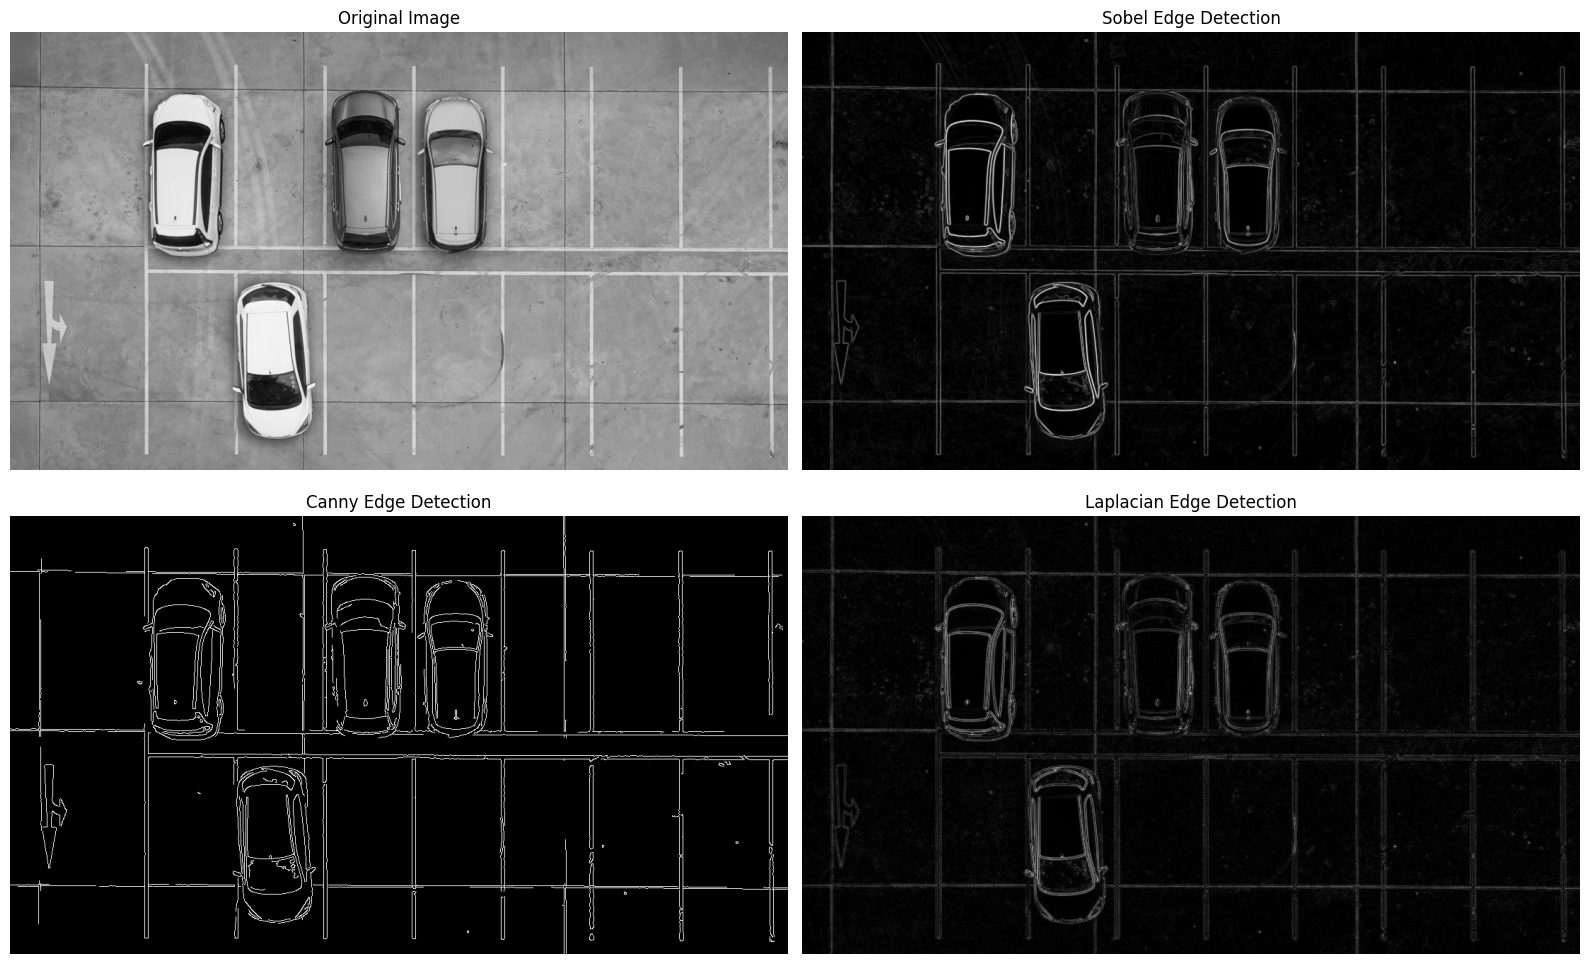

In [ ]:
# 4. Sobel, Canny, dan Laplacian Edge Detection
car = cv.imread(f"{BASE}/car-park.jpg", 0)
if car is None:
    car = cv.imread(f"{BASE}/car_park.jpg", 0)

# a. Sobel Edge Detection
sobelx = cv.Sobel(car, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(car, cv.CV_64F, 0, 1, ksize=3)
sobel_combined = cv.magnitude(sobelx, sobely)

# b. Canny Edge Detection
blur_car = cv.GaussianBlur(car, (3, 3), 0)
canny = cv.Canny(blur_car, 100, 200)

# c. Laplacian Edge Detection
laplacian = cv.Laplacian(blur_car, cv.CV_64F)
laplacian = np.uint8(np.absolute(laplacian))

plt.figure(figsize=(16, 10))
plt.subplot(2, 2, 1)
plt.imshow(car, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(sobel_combined, cmap='gray')
plt.title('Sobel Edge Detection')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(canny, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(laplacian, cmap='gray')
plt.title('Laplacian Edge Detection')
plt.axis('off')

plt.tight_layout()
plt.show()

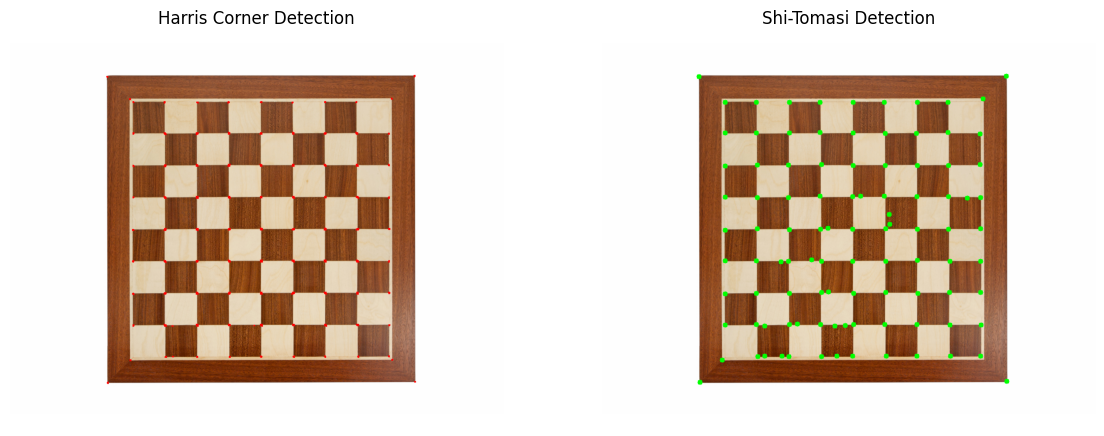

In [ ]:
# 5. Harris Corner Detection dan Shi-Tomasi Detection
chess = cv.imread(f"{BASE}/chess-board.jpg")
if chess is None:
    chess = cv.imread(f"{BASE}/chess_board.jpg")

gray_chess = cv.cvtColor(chess, cv.COLOR_BGR2GRAY)

# a. Harris Corner Detection
gray_f = np.float32(gray_chess)
dst = cv.cornerHarris(gray_f, blockSize=2, ksize=3, k=0.04)
dst = cv.dilate(dst, None)
harris_out = chess.copy()
harris_out[dst > 0.01 * dst.max()] = [0, 0, 255]

# b. Shi-Tomasi Detection (cv.goodFeaturesToTrack)
corners = cv.goodFeaturesToTrack(gray_chess, maxCorners=100, qualityLevel=0.01, minDistance=10)
corners = np.int32(corners)
shi_out = chess.copy()
for i in corners:
    x, y = i.ravel()
    cv.circle(shi_out, (x, y), 5, (0, 255, 0), -1)

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(harris_out, cv.COLOR_BGR2RGB))
plt.title('Harris Corner Detection')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(shi_out, cv.COLOR_BGR2RGB))
plt.title('Shi-Tomasi Detection')
plt.axis('off')
plt.show()

Garis awal: 31
Setelah penggabungan: 20


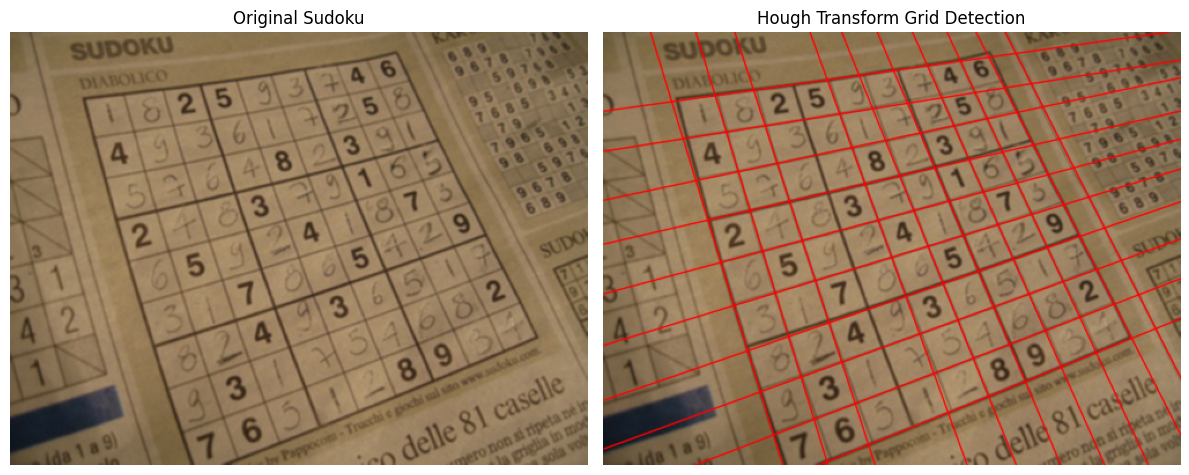

In [28]:
# 6. Hough Transform (Grid Detection) pada sudoku.jpg
sudoku = cv.imread(f"{BASE}/sudoku.jpg")
if sudoku is None:
    raise FileNotFoundError(f"Gambar tidak ditemukan: {BASE}/sudoku.jpg")

gray_sudoku = cv.cvtColor(sudoku, cv.COLOR_BGR2GRAY)

# 1. Canny Edge Detection
edges = cv.Canny(gray_sudoku, 50, 150, apertureSize=3)

# 2. Dilasi untuk menyambungkan tepi
kernel_dilasi = np.ones((3, 3), np.uint8)
dilated = cv.dilate(edges, kernel_dilasi, iterations=1)

# 3. Erosi untuk menipiskan hasil dilasi
kernel_erosi = np.ones((5, 5), np.uint8)
eroded = cv.erode(dilated, kernel_erosi, iterations=1)

# 4. Hough Transform
lines = cv.HoughLines(eroded, 1, np.pi / 180, threshold=160)

# 5. Gabungkan garis mirip dengan mempertahankan kandidat terkuat
merged_lines = []

if lines is not None:
    for rho, theta in lines[:, 0]:
        similar = False

        for old_rho, old_theta in merged_lines:
            angle_diff = abs(float(theta - old_theta))
            rho_diff = abs(float(rho - old_rho))

            if angle_diff > np.pi / 2:
                angle_diff = np.pi - angle_diff
                rho_diff = abs(float(rho + old_rho))

            if rho_diff < 12 and angle_diff < np.deg2rad(4):
                similar = True
                break

        if not similar:
            merged_lines.append((rho, theta))

# Gambar garis hasil deteksi
hough_out = sudoku.copy()
length = 2 * max(sudoku.shape[:2])

for rho, theta in merged_lines:
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho

    pt1 = (int(x0 - length * b), int(y0 + length * a))
    pt2 = (int(x0 + length * b), int(y0 - length * a))

    cv.line(hough_out, pt1, pt2, (0, 0, 255), 1, cv.LINE_AA)

print("Garis awal:", 0 if lines is None else len(lines))
print("Setelah penggabungan:", len(merged_lines))

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(sudoku, cv.COLOR_BGR2RGB))
plt.title("Original Sudoku")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(hough_out, cv.COLOR_BGR2RGB))
plt.title("Hough Transform Grid Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

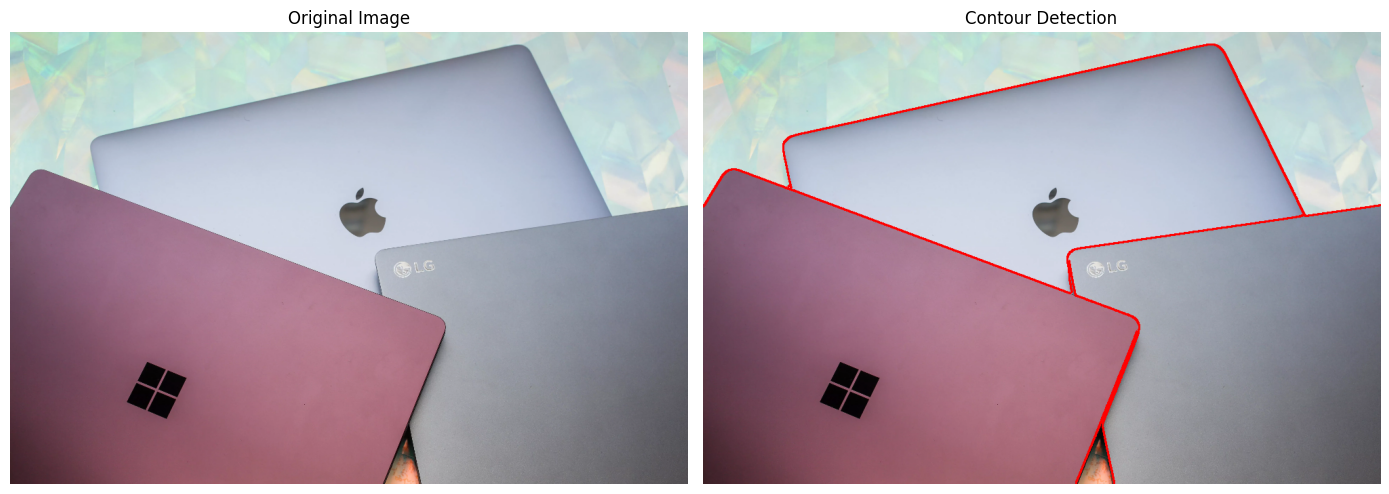

In [30]:
# 7. Contour Detection pada laptop.jpg
laptop = cv.imread(f"{BASE}/laptop.jpg")
if laptop is None:
    raise FileNotFoundError(f"Gambar tidak ditemukan: {BASE}/laptop.jpg")

# Samakan ukuran dengan ukuran yang digunakan saat pengujian
h, w = laptop.shape[:2]
laptop = cv.resize(laptop, (1000, round(h * 1000 / w)))

# Grayscale dan pengurangan noise
gray_laptop = cv.cvtColor(laptop, cv.COLOR_BGR2GRAY)
blurred = cv.GaussianBlur(gray_laptop, (5, 5), 0)

# Deteksi tepi
edges = cv.Canny(blurred, 30, 80)

# Cari kontur
contours, hierarchy = cv.findContours(
    edges,
    cv.RETR_LIST,
    cv.CHAIN_APPROX_SIMPLE
)

# Pertahankan kontur panjang; buang tekstur dan logo kecil
filtered_contours = [
    contour for contour in contours
    if cv.arcLength(contour, True) > 500
]

# Gambar kontur pada salinan gambar
contour_out = laptop.copy()
cv.drawContours(
    contour_out,
    filtered_contours,
    -1,
    (0, 0, 255),
    2
)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(laptop, cv.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(contour_out, cv.COLOR_BGR2RGB))
plt.title("Contour Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

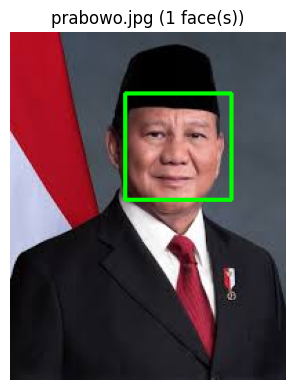

In [ ]:
# 8. Face Detection pada dataset facedet
import os, glob

# Path cascade classifier
cascade_path = f"{BASE}/haarcascades/haarcascade_frontalface_alt.xml"
face_cascade = cv.CascadeClassifier(cascade_path)
if face_cascade.empty():
    cascade_path = cv.data.haarcascades + 'haarcascade_frontalface_alt.xml'
    face_cascade = cv.CascadeClassifier(cascade_path)

# Cari daftar gambar di folder facedet
facedet_dir = f"{BASE}/facedet"
img_files = glob.glob(f"{facedet_dir}/*.jpg") + glob.glob(f"{facedet_dir}/*.png")
if not img_files:
    img_files = [f"{BASE}/prabowo.jpg", f"{BASE}/people.jpg", f"{BASE}/solvay.jpg"]

plt.figure(figsize=(16, 4 * ((len(img_files) + 2) // 3)))
for idx, fpath in enumerate(img_files[:6]):
    img_c = cv.imread(fpath)
    if img_c is None:
        continue
    gray_c = cv.cvtColor(img_c, cv.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray_c, scaleFactor=1.1, minNeighbors=4)
    for (x, y, w, h) in faces:
        cv.rectangle(img_c, (x, y), (x + w, y + h), (0, 255, 0), 2)

    plt.subplot((len(img_files[:6]) + 2) // 3, 3, idx + 1)
    plt.imshow(cv.cvtColor(img_c, cv.COLOR_BGR2RGB))
    fname = os.path.basename(fpath)
    plt.title(f"{fname} ({len(faces)} face(s))")
    plt.axis('off')

plt.tight_layout()
plt.show()

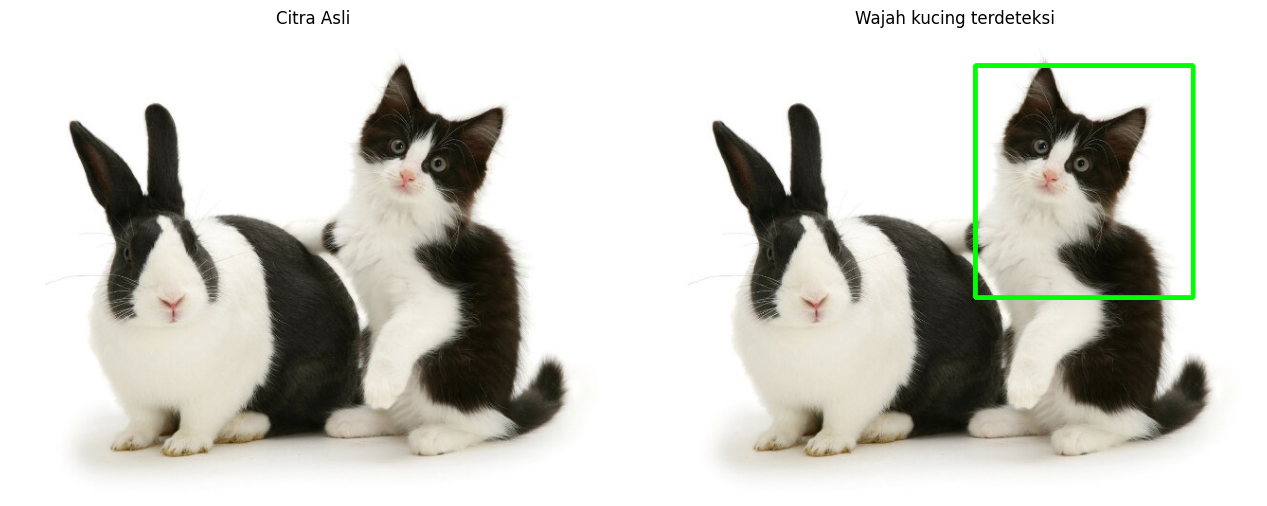

In [43]:
# 9. Deteksi Wajah Kucing dengan Template Matching
# Template wajah diambil dari cat-template.jpg, target dari cat-and-rabbit.jpg.
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

cat_scene = cv.imread(f"{BASE}/cat-and-rabbit.jpg")
cat_template = cv.imread(f"{BASE}/cat-template.jpg")

gray_scene = cv.cvtColor(cat_scene, cv.COLOR_BGR2GRAY)
gray_template = cv.cvtColor(cat_template, cv.COLOR_BGR2GRAY)

# Ambil area kepala dan wajah dari gambar template (x, y, lebar, tinggi).
x, y, w, h = 10, 5, 230, 245
face_template = gray_template[y:y+h, x:x+w]

# Cari template pada beberapa ukuran untuk mengakomodasi perbedaan skala.
best_score = -1
best_location = None
best_size = None
for scale in np.linspace(0.75, 1.15, 41):
    tw, th = int(w * scale), int(h * scale)
    if tw > gray_scene.shape[1] or th > gray_scene.shape[0]:
        continue
    resized = cv.resize(face_template, (tw, th))
    response = cv.matchTemplate(gray_scene, resized, cv.TM_CCOEFF_NORMED)
    _, score, _, location = cv.minMaxLoc(response)
    if score > best_score:
        best_score = score
        best_location = location
        best_size = (tw, th)

cat_out = cat_scene.copy()
threshold = 0.70
if best_score >= threshold:
    x1, y1 = best_location
    tw, th = best_size
    cv.rectangle(cat_out, (x1, y1), (x1 + tw, y1 + th), (0, 255, 0), 3)
    result_text = f'Wajah kucing terdeteksi'
else:
    result_text = f'Wajah tidak terdeteksi'

plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(cat_scene, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(cat_out, cv.COLOR_BGR2RGB))
plt.title(result_text)
plt.axis('off')

plt.tight_layout()
plt.show()

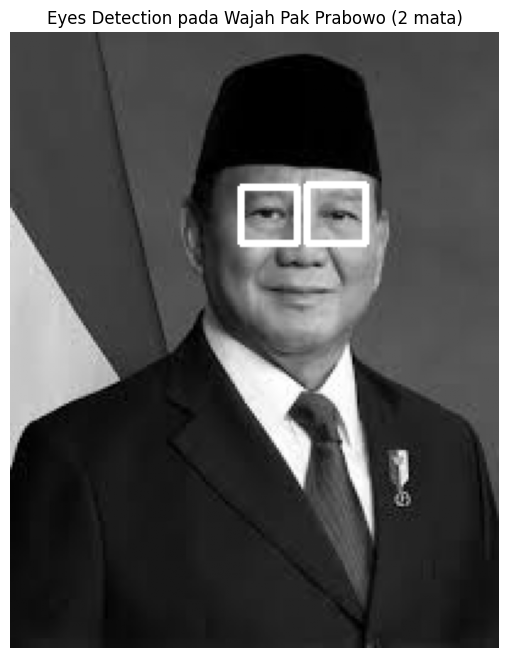

In [71]:
# 10. Eyes Detection pada wajah Pak Prabowo
import cv2 as cv
import matplotlib.pyplot as plt
from pathlib import Path

# Baca foto Prabowo dari folder facedet atau Images.
prabowo_path = Path(BASE) / 'facedet' / 'prabowo.jpg'
if not prabowo_path.exists():
    prabowo_path = Path(BASE) / 'prabowo.jpg'
if not prabowo_path.exists():
    raise FileNotFoundError(f'Tidak menemukan prabowo.jpg di {BASE}/facedet atau {BASE}')

prabowo = cv.imread(str(prabowo_path))
if prabowo is None:
    raise ValueError('Foto Prabowo tidak dapat dibaca.')
gray_prabowo = cv.cvtColor(prabowo, cv.COLOR_BGR2GRAY)

# Load cascade wajah dan mata bawaan OpenCV.
face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalface_alt.xml'
)
eye_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_eye.xml'
)
if face_cascade.empty() or eye_cascade.empty():
    raise FileNotFoundError('File Haar cascade wajah atau mata tidak ditemukan.')

faces = face_cascade.detectMultiScale(
    gray_prabowo, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40)
)

# Gambar hasil grayscale seperti contoh pada modul.
eye_result = gray_prabowo.copy()
eye_count = 0
for x, y, w, h in faces:
    # Fokuskan deteksi mata di bagian atas wajah.
    upper_face = gray_prabowo[y:y + int(h * 0.65), x:x + w]
    # Menurunkan minNeighbors dan scaleFactor agar lebih sensitif mendeteksi mata
    eyes = eye_cascade.detectMultiScale(
        upper_face, scaleFactor=1.05, minNeighbors=3, minSize=(12, 12)
    )
    for ex, ey, ew, eh in eyes:
        cv.rectangle(
            eye_result,
            (x + ex, y + ey),
            (x + ex + ew, y + ey + eh),
            255,
            2
        )
        eye_count += 1

plt.figure(figsize=(8, 8))
plt.imshow(eye_result, cmap='gray')
plt.title(f'Eyes Detection pada Wajah Pak Prabowo ({eye_count} mata)')
plt.axis('off')
plt.show()


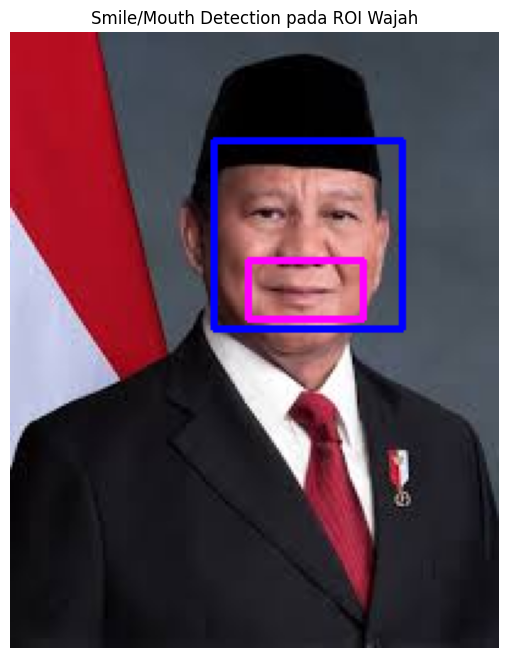

Smile terdeteksi: 1 deteksi


In [69]:
# Langkah 11: Smile/Mouth Detection dengan parameter yang lebih sensitif agar mendeteksi senyum
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Muat cascade wajah dan senyuman
face_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_alt.xml')
smile_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_smile.xml')

# Baca file gambar secara robust dengan Path
people_path = Path(BASE) / 'prabowo.jpg'
people = cv.imread(str(people_path))

gray_people = cv.cvtColor(people, cv.COLOR_BGR2GRAY)
faces = face_cascade.detectMultiScale(gray_people, scaleFactor=1.1, minNeighbors=4)

img_smile = people.copy()
total_smiles = 0

for (x, y, w, h) in faces:
    # Gambar penanda wajah
    cv.rectangle(img_smile, (x, y), (x + w, y + h), (255, 0, 0), 2)

    roi_gray = gray_people[y:y+h, x:x+w]
    roi_color = img_smile[y:y+h, x:x+w]

    # Fokus pada area mulut (bagian bawah wajah)
    mouth_y = int(roi_gray.shape[0] * 0.55)
    roi_mouth = roi_gray[mouth_y:, :]

    # Deteksi smile dengan parameter sensitivitas tinggi agar senyuman tipis/lebar dapat terdeteksi
    smiles = smile_cascade.detectMultiScale(roi_mouth, scaleFactor=1.1, minNeighbors=3, minSize=(15, 15))

    # Gambar rectangle pada area mulut yang terdeteksi
    for (sx, sy, sw, sh) in smiles:
        actual_sy = mouth_y + sy  # Offset karena ROI mouth
        cv.rectangle(roi_color, (sx, actual_sy), (sx + sw, actual_sy + sh), (255, 0, 255), 2)
        cv.putText(roi_color, '', (sx, actual_sy - 5), cv.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 255), 2)
        total_smiles += 1

plt.figure(figsize=(10, 8))
plt.imshow(cv.cvtColor(img_smile, cv.COLOR_BGR2RGB))
plt.title('Smile/Mouth Detection pada ROI Wajah')
plt.axis('off')
plt.show()

print(f'Smile terdeteksi: {total_smiles if total_smiles > 0 else "Tidak ada"} deteksi')

<IPython.core.display.Javascript object>

Foto tersimpan di: photo.jpg


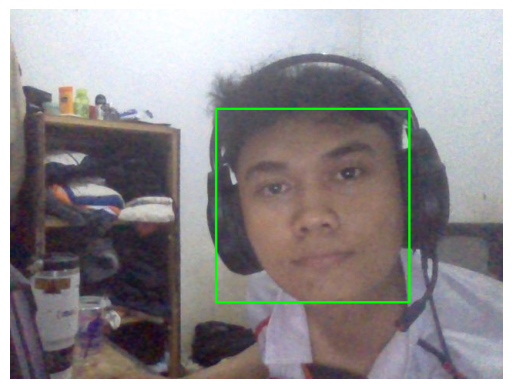

In [79]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
        async function takePhoto(quality) {
            const div = document.createElement('div');
            const capture = document.createElement('button');
            capture.textContent = 'Ambil Foto';
            div.appendChild(capture);

            const video = document.createElement('video');
            video.style.display = 'block';
            const stream = await navigator.mediaDevices.getUserMedia({video: true});

            document.body.appendChild(div);
            div.appendChild(video);
            video.srcObject = stream;
            await video.play();

            google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
            await new Promise((resolve) => capture.onclick = resolve);

            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);
            stream.getVideoTracks()[0].stop();
            div.remove();
            return canvas.toDataURL('image/jpeg', quality);
        }
    ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

try:
    filename = take_photo()
    print(f'Foto tersimpan di: {filename}')

    # Deteksi wajah pada foto webcam
    webcam_img = cv2.imread(filename)
    webcam_gray = cv2.cvtColor(webcam_img, cv2.COLOR_BGR2GRAY)
    faces_webcam = face_cascade.detectMultiScale(webcam_gray, 1.1, 4)
    for (x, y, w, h) in faces_webcam:
        cv2.rectangle(webcam_img, (x, y), (x + w, y + h), (0, 255, 0), 2)

    plt.imshow(cv2.cvtColor(webcam_img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()
except Exception as err:
    print('Webcam tidak aktif atau dibatalkan:', err)

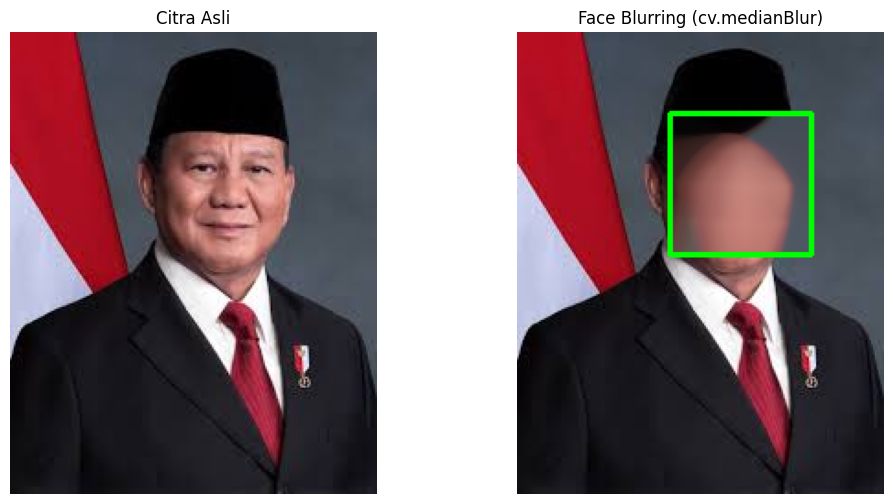

In [ ]:
# 13. Face Blurring pada Bagian Wajah yang Terdeteksi
face_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_alt.xml')

prabowo = cv.imread(f"{BASE}/facedet/prabowo.jpg")
if prabowo is None:
    prabowo = cv.imread(f"{BASE}/prabowo.jpg")

gray_p = cv.cvtColor(prabowo, cv.COLOR_BGR2GRAY)
faces = face_cascade.detectMultiScale(gray_p, scaleFactor=1.1, minNeighbors=4)

blurred_face_img = prabowo.copy()
for (x, y, w, h) in faces:
    roi = blurred_face_img[y:y+h, x:x+w]
    # Blurring wajah menggunakan cv.medianBlur
    roi_blurred = cv.medianBlur(roi, 55)
    blurred_face_img[y:y+h, x:x+w] = roi_blurred
    cv.rectangle(blurred_face_img, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(prabowo, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(blurred_face_img, cv.COLOR_BGR2RGB))
plt.title('Face Blurring (cv.medianBlur)')
plt.axis('off')
plt.show()

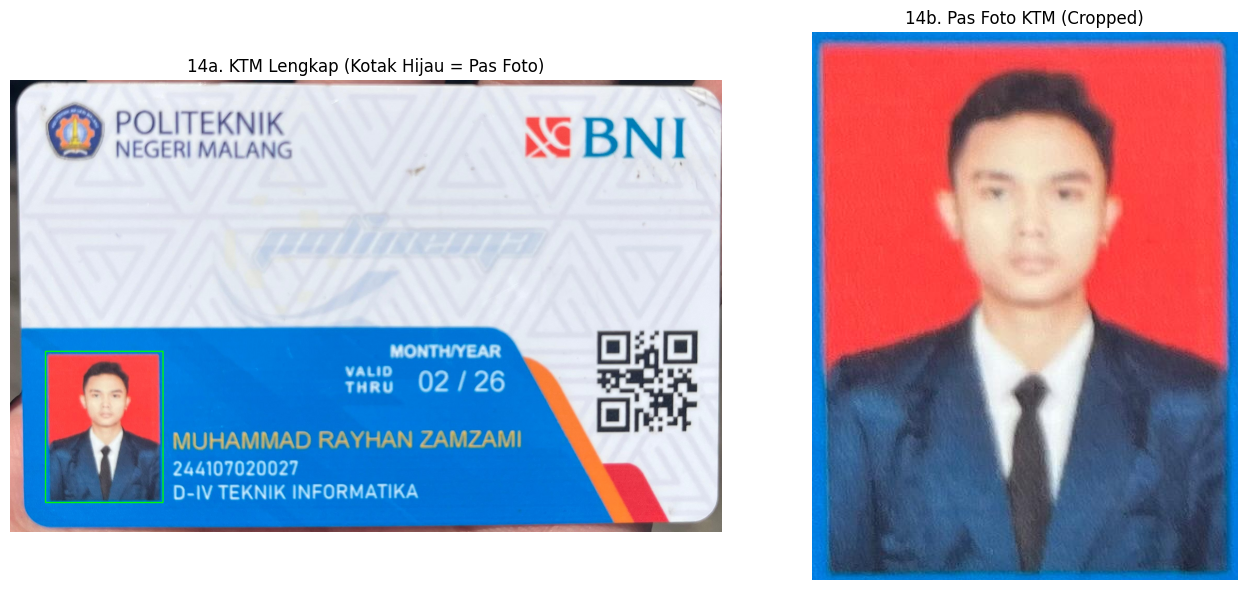

Koordinat crop: x=136:588, y=1044:1626


In [81]:
ktm_file = BASE + '/KTM1d.jpeg'
ktm_img = cv2.imread(ktm_file)

if ktm_img is None:
    print('File KTM tidak ditemukan atau tidak bisa dibaca.')
else:
    h, w = ktm_img.shape[:2]

    # Area pas foto di KTM: kiri bawah
    x1, x2 = int(w * 0.05), int(w * 0.215)
    y1, y2 = int(h * 0.60), int(h * 0.935)

    foto_ktm = ktm_img[y1:y2, x1:x2]

    ktm_with_box = ktm_img.copy()
    cv2.rectangle(ktm_with_box, (x1, y1), (x2, y2), (0, 255, 0), 3)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].imshow(cv2.cvtColor(ktm_with_box, cv2.COLOR_BGR2RGB))
    axes[0].set_title('14a. KTM Lengkap (Kotak Hijau = Pas Foto)')
    axes[0].axis('off')

    axes[1].imshow(cv2.cvtColor(foto_ktm, cv2.COLOR_BGR2RGB))
    axes[1].set_title('14b. Pas Foto KTM (Cropped)')
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

    print(f'Koordinat crop: x={x1}:{x2}, y={y1}:{y2}')

In [102]:
import os
import cv2
from tensorflow.keras.datasets import mnist
from tqdm import tqdm

# Download dataset angka 0–9, lalu siapkan 300 gambar per angka
(x_train, y_train), _ = mnist.load_data()

DATASET_DIR = "dataset/training"
os.makedirs(DATASET_DIR, exist_ok=True)

for angka in range(10):
    folder = os.path.join(DATASET_DIR, str(angka))
    os.makedirs(folder, exist_ok=True)

    indeks = [i for i, label in enumerate(y_train) if label == angka][:300]

    for nomor, i in enumerate(tqdm(indeks, desc=f"Angka {angka}")):
        gambar = cv2.resize(x_train[i], (100, 100))
        cv2.imwrite(os.path.join(folder, f"{angka}_{nomor:03}.png"), gambar)

print("Dataset angka 0–9 sudah dibuat di:", DATASET_DIR)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Angka 9: 100%|██████████| 300/300 [00:00<00:00, 7153.32it/s]

Dataset angka 0–9 sudah dibuat di: dataset/training


In [105]:
import pickle
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

# Load data dari pickle
X = pickle.load(open('X.pickle', 'rb'))
Y = pickle.load(open('Y.pickle', 'rb'))

jumlah_kelas = len(pickle.load(open('kelas.pickle', 'rb')))
Y = to_categorical(Y, num_classes=jumlah_kelas)
X = X / 255.0
width, height = 100, 100

# Arsitektur CNN sesuai modul
inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# Training model
val_split = 0.2 if len(X) >= 5 else 0.0
riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=val_split)
model.save('anpr.keras')

print('Training selesai!')
print('Akurasi training terakhir:', riwayat.history['accuracy'][-1])

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100, 100, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d (ZeroPadding2D)  │ (None, 104, 104, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 100, 100, 16)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 46, 46, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28224)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     7,225,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,275,498 (27.75 MB)

 Trainable params: 7,275,498 (27.75 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 25s 317ms/step - accuracy: 0.7092 - loss: 1.0748 - val_accuracy: 0.8733 - val_loss: 0.3841
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 41s 315ms/step - accuracy: 0.8963 - loss: 0.3346 - val_accuracy: 0.9317 - val_loss: 0.2592
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 24s 315ms/step - accuracy: 0.9329 - loss: 0.2305 - val_accuracy: 0.9333 - val_loss: 0.2141
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 42s 324ms/step - accuracy: 0.9583 - loss: 0.1502 - val_accuracy: 0.9467 - val_loss: 0.1865
Epoch 5/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 42s 335ms/step - accuracy: 0.9692 - loss: 0.1029 - val_accuracy: 0.9467 - val_loss: 0.1584
Epoch 6/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 24s 318ms/step - accuracy: 0.9804 - loss: 0.0663 - val_accuracy: 0.9533 - val_loss: 0.1599
Epoch 7/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 41s 322ms/step - accuracy: 0.9921 - loss: 0.0359 - val_accuracy: 0.9500 - val_loss: 0.1741
Epoch 8/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 41s 320ms/step - accuracy: 0.9937 - loss: 0.0220 - val_accu

In [107]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = BASE + 'dataset/testing'
width, height = 100, 100

model = tf.keras.models.load_model('anpr.keras')
dirs = pickle.load(open('kelas.pickle', 'rb'))

if os.path.exists(data_dir_testing):
    for folder_item in sorted(os.listdir(data_dir_testing)):
        temp = ''
        folder = os.path.join(data_dir_testing, folder_item)
        if not os.path.isdir(folder):
            continue
        for char_img in sorted(os.listdir(folder)):
            img_array = cv2.imread(os.path.join(folder, char_img), cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (width, height))
            new_array = new_array.reshape(-1, width, height, 1) / 255.0
            prediction = model.predict(new_array, verbose=0)
            temp += dirs[np.argmax(prediction[0])]
        print(f'Folder: {folder_item} -> Prediksi Karakter: {temp}')
else:
    print('Folder testing belum dibuat atau berada di lokasi berbeda.')
    print('Contoh pengujian satu gambar karakter:')
    sample_test = np.zeros((1, 100, 100, 1), dtype=np.float32)
    pred = model.predict(sample_test, verbose=0)
    print('Prediksi kelas karakter:', dirs[np.argmax(pred[0])])

Folder testing belum dibuat atau berada di lokasi berbeda.
Contoh pengujian satu gambar karakter:
Prediksi kelas karakter: 5
